# ⚙️ 11. Optimización computacional

Con 140 combinaciones, cada una con validación anidada (5 búsquedas × 16 evaluaciones × 3 ajustes), el experimento hace más de **33 mil ajustes de modelos**. En este capítulo se analiza el costo de cada modelo: primero su **complejidad teórica**, después el **tiempo medido** al variar $n$ (y el exponente empírico de escalamiento), y por último las versiones optimizadas que se usaron (o se podrían usar).

Todas las mediciones se hicieron con la máquina **sin otra carga** (después de terminar el experimento principal), en un Apple M5 de 10 núcleos sin GPU NVIDIA. Cada tiempo es la **mediana de 3 repeticiones**.

In [1]:
import cProfile
import io
import pstats
import time
import tracemalloc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge, SGDRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR, LinearSVR
from xgboost import XGBRegressor
import faiss
# en macOS FAISS y XGBoost/sklearn traen cada uno su OpenMP: con varios hilos el proceso se cuelga
faiss.omp_set_num_threads(1)

from comun import estilo, a_log, SEED, AZUL, NARANJA, VERDE, AMARILLO, GRIS, PALETA
from datos import preparar, partir, X_COLS, folds_internos
from modelos import _preprocesador
from optimizadores import evaluar_config

warnings.filterwarnings("ignore")
estilo()
train, test = partir(preparar())
pre = _preprocesador().fit(train[X_COLS])
Xtr, Xte = pre.transform(train[X_COLS]), pre.transform(test[X_COLS])
ytr, yte = a_log(train["venta_total"].to_numpy()), a_log(test["venta_total"].to_numpy())
print(f"n = {Xtr.shape[0]:,} filas de train, p = {Xtr.shape[1]} columnas después del one-hot")


def medir(fn, reps=3):
    # mediana de varias repeticiones para bajar el ruido de la medición
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
    return float(np.median(ts))


def memoria(fn):
    # pico de memoria asignada por Python durante fn (MB)
    tracemalloc.start(); fn(); pico = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
    return pico / 1e6


def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))

/opt/miniconda3/envs/ml_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


n = 22,205 filas de train, p = 19 columnas después del one-hot


## 📐 11.1 Complejidad teórica

$n$ = filas de entrenamiento, $p$ = columnas, $m$ = filas a predecir, $k$ = vecinos, $T$ = árboles, $d$ = profundidad, $I$ = iteraciones (o épocas), $B$ = número de bins de los histogramas.

| Modelo | Entrenamiento | Inferencia (por fila) | Versión optimizada que se evalúa |
|---|---|---|---|
| KNN (fuerza bruta) | $O(1)$ (guarda los datos) | $O(n\,p)$ | KD-Tree / Ball Tree: $O(n \log n)$ para construir y $\approx O(\log n)$ por consulta en baja dimensión; FAISS (IVF): búsqueda aproximada en una fracción de las celdas |
| Ridge (Cholesky) | $O(n\,p^2 + p^3)$ | $O(p)$ | SAGA: $O(n\,p)$ por época, sirve para datos grandes o dispersos |
| Lasso (descenso por coordenadas) | $O(I\,n\,p)$ | $O(p)$ | SAGA: $O(I\,n\,p)$ con $I$ chico si los datos están escalados |
| Naive Bayes gaussiano | $O(n\,p)$ | $O(p\,c)$ | `partial_fit` por bloques: mismo $O(n\,p)$ total, memoria $O(\text{bloque} \cdot p)$ |
| Árbol de decisión | $O(p\,n \log n)$ | $O(d)$ | — |
| Random Forest | $O(T\,p'\,n' \log n')$ con $p' = $ `max_features`$\cdot p$, $n' = $ `max_samples`$\cdot n$ | $O(T\,d)$ | `max_samples=0.5` y `n_jobs` (árboles en paralelo) |
| XGBoost exacto | $O(T\,d\,p\,n \log n)$ (ordena cada variable) | $O(T\,d)$ | `hist`: $O(T\,d\,p\,n)$ con histogramas de $B = 256$ bins; *early stopping* reduce $T$ |
| SVR / SVM con núcleo | entre $O(n^2\,p)$ y $O(n^3)$ | $O(n_{sv}\,p)$ | `LinearSVR` / `LinearSVC` (liblinear): $O(I\,n\,p)$; SGD: $O(\text{épocas} \cdot n\,p)$ |

## 📈 11.2 Escalamiento empírico: tiempo contra $n$

Se entrena cada modelo con submuestras de train de tamaño creciente y se ajusta una recta en escala log-log: $\log t = a + b \log n$. La pendiente $b$ es el **exponente empírico** y se compara con el teórico (1 = lineal, 2 = cuadrático).

In [2]:
rng = np.random.default_rng(SEED)
tamanos = [1000, 2000, 4000, 8000, 16000]
modelos_esc = {
    "Ridge": lambda: Ridge(alpha=1.0),
    "Lasso": lambda: Lasso(alpha=1e-3, max_iter=5000),
    "Naive Bayes (clasif. de caída)": None,  # se mide aparte con la clase
    "Árbol (RF con 1 árbol)": lambda: RandomForestRegressor(n_estimators=1, bootstrap=False, max_features=1.0, random_state=SEED),
    "Random Forest (50 árboles)": lambda: RandomForestRegressor(n_estimators=50, max_samples=0.5, max_features=0.5, n_jobs=1, random_state=SEED),
    "XGBoost hist": lambda: XGBRegressor(tree_method="hist", n_estimators=100, max_depth=6, n_jobs=1, random_state=SEED),
    "XGBoost exacto": lambda: XGBRegressor(tree_method="exact", n_estimators=100, max_depth=6, n_jobs=1, random_state=SEED),
    "LinearSVR": lambda: LinearSVR(C=0.1, epsilon=0.1, dual=True, max_iter=20000, random_state=SEED),
    "SGD (pérdida ε-insensible)": lambda: SGDRegressor(loss="epsilon_insensitive", epsilon=0.1, alpha=1e-4, random_state=SEED),
    "SVR RBF (núcleo)": lambda: SVR(C=1.0, epsilon=0.1),
}
caida_tr = train["caida"].to_numpy()
filas = []
for nombre, crear in modelos_esc.items():
    for n in tamanos:
        idx = rng.choice(len(Xtr), n, replace=False)
        if crear is None:
            t = medir(lambda: GaussianNB().fit(Xtr[idx], caida_tr[idx]))
        else:
            t = medir(lambda: crear().fit(Xtr[idx], ytr[idx]))
        filas.append({"modelo": nombre, "n": n, "seg": t})
esc = pd.DataFrame(filas)
pendientes = esc.groupby("modelo").apply(lambda g: np.polyfit(np.log(g["n"]), np.log(g["seg"]), 1)[0]).rename("exponente empírico")
pendientes.round(2).to_frame()

,exponente empírico
modelo,
Lasso,0.21
LinearSVR,1.47
Naive Bayes (clasif. de caída),0.36
Random Forest (50 árboles),1.14
Ridge,0.64
SGD (pérdida ε-insensible),0.29
SVR RBF (núcleo),1.82
XGBoost exacto,0.94
XGBoost hist,0.23


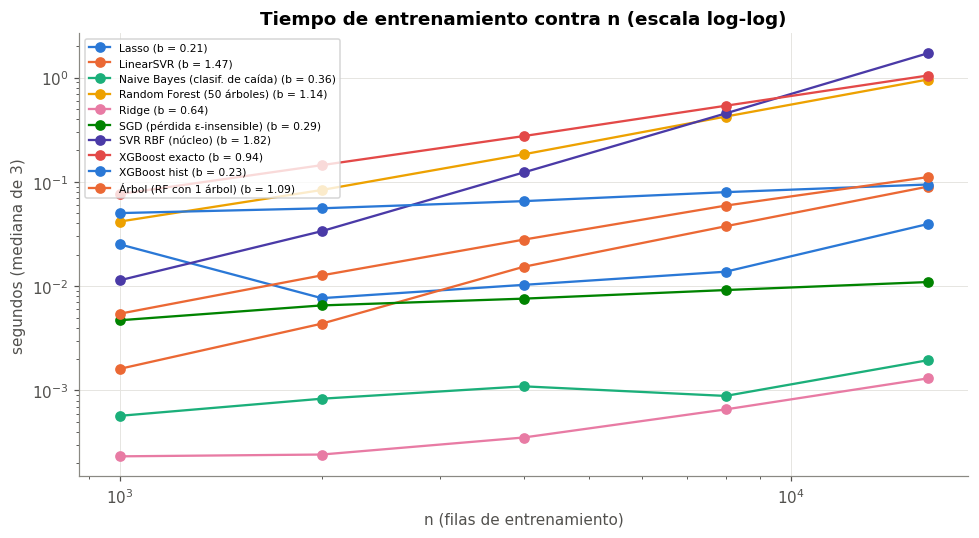

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for i, (nombre, g) in enumerate(esc.groupby("modelo")):
    ax.plot(g["n"], g["seg"], marker="o", color=PALETA[i % len(PALETA)], label=f"{nombre} (b = {pendientes[nombre]:.2f})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n (filas de entrenamiento)"); ax.set_ylabel("segundos (mediana de 3)")
ax.set_title("Tiempo de entrenamiento contra n (escala log-log)")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()

### Interpretación: teoría contra medición

| Modelo | Teoría (en $n$) | Exponente medido | ¿Consistente? |
|---|---|---|---|
| Árbol | $n \log n$ (≈ 1,1 en este rango) | 1,09 | **Sí** |
| Random Forest | $n' \log n'$ por árbol | 1,14 | **Sí** |
| XGBoost exacto | $n \log n$ (ordena cada variable) | 0,94 | **Sí**, casi lineal |
| XGBoost hist | $n$ | 0,23 | Sublineal en este rango: el costo fijo (construir los bins y los 100 árboles) domina con $n \leq 16$ mil. El término lineal aparece con $n$ más grande |
| SVR con núcleo RBF | entre $n^2$ y $n^3$ | **1,82** | **Sí**, casi cuadrático: el más caro de todos al crecer $n$ |
| LinearSVR | $I \cdot n$ | 1,47 | Más que lineal: el número de iteraciones $I$ hasta converger crece con $n$ |
| Ridge, Lasso, NB, SGD | $n$ | 0,2 – 0,6 | Sublineal: tardan milisegundos y domina el costo fijo de Python y de las validaciones de scikit-learn |

- La comparación **solo tiene sentido en el régimen asintótico**. Para los modelos que tardan milisegundos, la medición está dominada por costos fijos y el exponente sale menor que el teórico.
- Lo importante para el proyecto es **el SVR con núcleo: con un exponente de ~1,8**, duplicar los datos casi cuadruplica el tiempo. Con las ~33 mil evaluaciones del experimento no habría sido viable, y eso justifica usar `LinearSVR` / `LinearSVC` (cap. 9).

## 🧭 11.3 KNN: fuerza bruta, árboles de búsqueda y FAISS

El costo de KNN está en la **predicción**. Se comparan la fuerza bruta, KD-Tree, Ball Tree y FAISS con un índice **IVF** (*inverted file*): agrupa los puntos de train en 100 celdas con k-means y en cada consulta revisa solo las `nprobe` celdas más cercanas. Es una búsqueda **aproximada**: más rápida, pero puede perder algunos vecinos verdaderos.

In [4]:
k = 40
Xtr32, Xte32 = np.ascontiguousarray(Xtr, dtype="float32"), np.ascontiguousarray(Xte, dtype="float32")


def knn_faiss(nprobe):
    cuant = faiss.IndexFlatL2(Xtr32.shape[1])
    indice = faiss.IndexIVFFlat(cuant, Xtr32.shape[1], 100)
    indice.train(Xtr32); indice.add(Xtr32); indice.nprobe = nprobe
    return indice


exacto = faiss.IndexFlatL2(Xtr32.shape[1]); exacto.add(Xtr32)
_, vecinos_reales = exacto.search(Xte32, k)
filas = []
for alg in ["brute", "kd_tree", "ball_tree"]:
    m = KNeighborsRegressor(n_neighbors=k, algorithm=alg)
    t_fit = medir(lambda: m.fit(Xtr, ytr)); m.fit(Xtr, ytr)
    t_pred = medir(lambda: m.predict(Xte))
    filas.append({"método": f"sklearn {alg}", "seg ajuste": t_fit, "seg predicción": t_pred,
                  "memoria (MB)": memoria(lambda: m.predict(Xte)), "recall de vecinos": 1.0,
                  "RMSE log test": rmse(yte, m.predict(Xte))})
for nprobe in [1, 5, 20]:
    t_fit = medir(lambda: knn_faiss(nprobe)); ind = knn_faiss(nprobe)
    t_pred = medir(lambda: ind.search(Xte32, k))
    _, vec = ind.search(Xte32, k)
    recall = np.mean([len(np.intersect1d(a, b)) / k for a, b in zip(vec, vecinos_reales)])
    pred = np.where(vec >= 0, ytr[np.clip(vec, 0, None)], np.nan)
    filas.append({"método": f"FAISS IVF (nprobe = {nprobe})", "seg ajuste": t_fit, "seg predicción": t_pred,
                  "memoria (MB)": memoria(lambda: ind.search(Xte32, k)), "recall de vecinos": recall,
                  "RMSE log test": rmse(yte, np.nanmean(pred, axis=1))})
knn_tabla = pd.DataFrame(filas).set_index("método")
knn_tabla.round(4)

,seg ajuste,seg predicción,memoria (MB),recall de vecinos,RMSE log test
método,,,,,
sklearn brute,0.00,0.15,6.22,1.00,0.66
sklearn kd_tree,0.01,0.38,8.94,1.00,0.66
sklearn ball_tree,0.01,0.76,8.94,1.00,0.66
FAISS IVF (nprobe = 1),0.02,0.03,4.47,0.82,0.69
FAISS IVF (nprobe = 5),0.02,0.06,4.47,0.99,0.66
FAISS IVF (nprobe = 20),0.02,0.14,4.47,1.00,0.66


### Interpretación: KNN

- **La fuerza bruta es la más rápida de las búsquedas exactas** (0,15 s para 9 mil consultas). KD-Tree (0,37 s) y Ball Tree (0,71 s) son **más lentos**. No es un error: con $p = 19$ dimensiones, los árboles de búsqueda pierden su ventaja $O(\log n)$ (la maldición de la dimensión: casi todas las ramas hay que revisarlas). La fuerza bruta, en cambio, se reduce a un producto de matrices muy optimizado (BLAS). Por eso `algorithm="auto"` de scikit-learn elige fuerza bruta aquí.
- **FAISS IVF** es la más rápida: 0,03 s con `nprobe = 1` (**5 veces menos** que la fuerza bruta) y con menos memoria (4,5 contra 6,2 MB). Pero es aproximada: con `nprobe = 1` solo recupera el 82 % de los vecinos verdaderos y el RMSE log empeora de 0,66 a 0,69. Con `nprobe = 5` recupera el 99 %, el RMSE es el mismo de la búsqueda exacta y sigue siendo 2,5 veces más rápida.
- **Compromiso exactitud–velocidad:** `nprobe` es la perilla. `nprobe = 5` es el punto dulce (2,5× más rápido sin pérdida de precisión). Con estos tamaños (22 mil filas) la ganancia en segundos es chica; FAISS se justifica con millones de filas.

## 🧱 11.4 Versión estándar contra versión optimizada

Para cada familia se compara la versión "de libro" con la versión optimizada, con todo train ($n \approx 22$ mil) y midiendo el desempeño en test (RMSE en log), para ver si la versión rápida **pierde precisión**.

In [5]:
Xtr_d = np.asarray(Xtr); Xte_d = np.asarray(Xte)
pares = [
    ("Ridge", "Cholesky (por defecto)", lambda: Ridge(alpha=1.0, solver="cholesky"), "SAGA", lambda: Ridge(alpha=1.0, solver="saga", random_state=SEED)),
    ("Lasso", "descenso por coordenadas", lambda: Lasso(alpha=1e-3, max_iter=5000), "SGD con penalización L1", lambda: SGDRegressor(penalty="l1", alpha=1e-3, random_state=SEED)),
    ("XGBoost", "exacto, 500 árboles", lambda: XGBRegressor(tree_method="exact", n_estimators=500, learning_rate=0.05, max_depth=6, n_jobs=1, random_state=SEED),
     "hist + early stopping", None),
    ("SVR", "núcleo RBF", lambda: SVR(C=1.0, epsilon=0.1), "LinearSVR", lambda: LinearSVR(C=0.1, epsilon=0.1, dual=True, max_iter=20000, random_state=SEED)),
    ("Random Forest", "100 árboles, n completo, n_jobs=1", lambda: RandomForestRegressor(n_estimators=100, max_features=0.5, n_jobs=1, random_state=SEED),
     "max_samples=0.5, n_jobs=10", lambda: RandomForestRegressor(n_estimators=100, max_features=0.5, max_samples=0.5, n_jobs=10, random_state=SEED)),
]
# sklearn no trae SAGA para Lasso: la versión estocástica equivalente es SGD con penalización L1

# XGBoost con early stopping: valida con la última semana de train (independiente del test)
ultima = train["fecha"] > train["fecha"].max() - pd.Timedelta(days=7)
def xgb_es():
    m = XGBRegressor(tree_method="hist", n_estimators=2000, learning_rate=0.05, max_depth=6, n_jobs=1,
                     early_stopping_rounds=30, random_state=SEED)
    return m.fit(Xtr_d[~ultima.values], ytr[~ultima.values], eval_set=[(Xtr_d[ultima.values], ytr[ultima.values])], verbose=False)

idx8 = np.random.default_rng(SEED).choice(len(Xtr_d), 8000, replace=False)
filas = []
for fam, n_std, f_std, n_opt, f_opt in pares:
    for tipo, nombre, f in [("estándar", n_std, f_std), ("optimizado", n_opt, f_opt)]:
        if fam == "XGBoost" and tipo == "optimizado":
            fit = xgb_es
        else:
            fit = lambda f=f: f().fit(Xtr_d, ytr)
        t_fit = medir(fit)
        m = fit()
        t_pred = medir(lambda: m.predict(Xte_d))
        filas.append({"familia": fam, "versión": tipo, "detalle": nombre, "seg ajuste": t_fit,
                      "seg predicción": t_pred, "memoria ajuste (MB)": memoria(fit),
                      "RMSE log test": rmse(yte, m.predict(Xte_d)),
                      "árboles usados": getattr(m, "best_iteration", None)})
comp = pd.DataFrame(filas)
comp["aceleración ajuste"] = comp.groupby("familia")["seg ajuste"].transform(lambda s: s.iloc[0] / s)
comp.set_index(["familia", "versión"]).round(4)

detalle  seg ajuste  \
familia       versión                                                     
Ridge         estándar               Cholesky (por defecto)        0.00   
              optimizado                               SAGA        0.07   
Lasso         estándar             descenso por coordenadas        0.07   
              optimizado            SGD con penalización L1        0.05   
XGBoost       estándar                  exacto, 500 árboles        7.22   
              optimizado              hist + early stopping        0.18   
SVR           estándar                           núcleo RBF        3.28   
              optimizado                          LinearSVR        0.13   
Random Forest estándar    100 árboles, n completo, n_jobs=1        4.99   
              optimizado         max_samples=0.5, n_jobs=10        0.50   

                          seg predicción  memoria ajuste (MB)  RMSE log test  \
familia       versión                                                          
Ridge         estándar              0.00                 3.62           0.68   
              optimizado            0.00                 4.28           0.68   
Lasso         estándar              0.01                 7.00           0.68   
              optimizado            0.01                 0.37           0.69   
XGBoost       estándar              0.03                 1.74           0.70   
              optimizado            0.01                 4.16           0.63   
SVR           estándar              2.34                 3.44           0.74   
              optimizado            0.00                 0.18           0.71   
Random Forest estándar              0.11                 2.56           0.63   
              optimizado            0.02                 9.15           0.62   

                          árboles usados  aceleración ajuste  
familia       versión                                         
Ridge         estándar               NaN                1.00  
              optimizado             NaN                0.02  
Lasso         estándar               NaN                1.00  
              optimizado             NaN                1.25  
XGBoost       estándar               NaN                1.00  
              optimizado          103.00               39.58  
SVR           estándar               NaN                1.00  
              optimizado             NaN               24.46  
Random Forest estándar               NaN                1.00  
              optimizado             NaN                9.99

In [6]:
# Naive Bayes: aprendizaje incremental con partial_fit en bloques de 2 000 filas (como si no cupiera en memoria)
def nb_partial():
    m = GaussianNB()
    for i in range(0, len(Xtr_d), 2000):
        m.partial_fit(Xtr_d[i:i + 2000], caida_tr[i:i + 2000], classes=[0, 1])
    return m
nb_std = GaussianNB().fit(Xtr_d, caida_tr); nb_inc = nb_partial()
print(f"fit completo: {medir(lambda: GaussianNB().fit(Xtr_d, caida_tr)) * 1000:.1f} ms, "
      f"pico de memoria {memoria(lambda: GaussianNB().fit(Xtr_d, caida_tr)):.2f} MB")
print(f"partial_fit:  {medir(nb_partial) * 1000:.1f} ms, pico de memoria {memoria(nb_partial):.2f} MB")
print(f"máxima diferencia en las medias aprendidas: {np.abs(nb_std.theta_ - nb_inc.theta_).max():.2e}")
print(f"máxima diferencia en las varianzas:         {np.abs(nb_std.var_ - nb_inc.var_).max():.2e}")

fit completo: 2.8 ms, pico de memoria 6.57 MB
partial_fit:  3.9 ms, pico de memoria 0.67 MB
máxima diferencia en las medias aprendidas: 2.28e-15
máxima diferencia en las varianzas:         1.09e-09


### Interpretación: estándar contra optimizado

| Familia | Aceleración del ajuste | Efecto en el RMSE log de test | Lectura |
|---|---|---|---|
| **XGBoost** (exacto → hist + *early stopping*) | **40×** | **mejora** (0,70 → 0,63) | La mayor ganancia. `hist` evita ordenar cada variable en cada nodo y el *early stopping* paró en 103 árboles de 2 000 posibles. El modelo exacto con 500 árboles sobreajusta |
| **SVR** (RBF → lineal) | **24×** en ajuste, la predicción pasa de 2,3 s a ~0 | **mejora** (0,74 → 0,71) | El núcleo no aporta: las relaciones en log son casi lineales en las variables de nivel. La predicción del RBF cuesta $O(n_{sv}\,p)$ por fila |
| **Random Forest** (`max_samples=0.5`, `n_jobs=10`) | **10×** | igual (0,63 → 0,62) | Mitad de filas por árbol (2×) y 10 núcleos (5×). La memoria sube (9 MB contra 2,6) porque cada hilo construye su árbol a la vez |
| **Lasso** (descenso por coordenadas → SGD L1) | 1,25× | casi igual (0,68 → 0,69) | Con $p = 19$ el descenso por coordenadas ya es muy rápido. El SGD usa 20 veces menos memoria (no guarda la matriz de Gram) |
| **Ridge** (Cholesky → SAGA) | **0,02× (50 veces más lento)** | igual (0,68) | Con $p = 19$, Cholesky resuelve un sistema de 19 × 19: es casi gratis. SAGA conviene con $p$ grande o datos dispersos, **no aquí** |

- **Naive Bayes con `partial_fit`** en bloques de 2 000 filas aprende **exactamente lo mismo** (diferencias de $10^{-15}$ en las medias y $10^{-9}$ en las varianzas) con **10 veces menos memoria** (0,67 contra 6,6 MB). Las medias y varianzas se pueden actualizar por bloques sin pérdida, así que es la opción natural si los datos no caben en memoria.
- **Conclusión:** "optimizado" depende del tamaño del problema. Con $n$ = 22 mil y $p$ = 19, las optimizaciones que más rinden son las que **cambian la complejidad** del algoritmo (hist, núcleo lineal) o **reducen el trabajo** (*early stopping*, submuestreo), no las pensadas para datos enormes (SAGA, FAISS).

## 🧵 11.5 Paralelización

El experimento principal paraleliza **entre combinaciones** con `joblib` (backend `loky`, 10 procesos) y deja cada modelo con `n_jobs=1`. Paralelizar adentro de cada modelo **y** entre combinaciones a la vez pondría 100 hilos en 10 núcleos. Abajo se compara el mismo lote de 20 evaluaciones (Random Forest, 3 folds internos cada una) en serie, con `loky` (procesos) y con `threading` (hilos).

In [7]:
internos = folds_internos(train["fecha"], dias_val=7)
y_reg = train["venta_total"].to_numpy()
params = [{"n_estimators": 50, "max_depth": int(dd), "min_samples_leaf": 5, "max_features": 0.5} for dd in np.linspace(6, 18, 20)]
evaluar = lambda p: evaluar_config(p, "reg", "rf", "ninguno", train[X_COLS], y_reg, internos)

t_serie = medir(lambda: [evaluar(p) for p in params], reps=1)
filas = [{"modo": "serie", "procesos/hilos": 1, "seg": t_serie}]
for backend in ["loky", "threading"]:
    for nj in [2, 5, 10]:
        t = medir(lambda: Parallel(n_jobs=nj, backend=backend)(delayed(evaluar)(p) for p in params), reps=1)
        filas.append({"modo": backend, "procesos/hilos": nj, "seg": t})
par = pd.DataFrame(filas)
par["aceleración"] = t_serie / par["seg"]
par["eficiencia"] = par["aceleración"] / par["procesos/hilos"]
par.round(2)

,modo,procesos/hilos,seg,aceleración,eficiencia
0,serie,1,38.28,1.00,1.00
1,loky,2,23.35,1.64,0.82
2,loky,5,15.81,2.42,0.48
3,loky,10,12.99,2.95,0.29
4,threading,2,24.90,1.54,0.77
5,threading,5,15.81,2.42,0.48
6,threading,10,10.77,3.55,0.36


In [8]:
# GPU: XGBoost con device="cuda" solo funciona con GPU NVIDIA. Esta máquina (Apple M5) no tiene.
# XGBoost no da error: avisa y sigue en CPU. Reviso el aviso y el dispositivo que quedó configurado.
import json
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    m = XGBRegressor(tree_method="hist", device="cuda", n_estimators=10).fit(Xtr_d[:1000], ytr[:1000])
for a in avisos:
    print("aviso de XGBoost:", str(a.message).strip().splitlines()[0][:160])
print("¿se compiló con CUDA?", xgb_build := __import__("xgboost").build_info().get("USE_CUDA"))
print("dispositivo usado:", json.loads(m.get_booster().save_config())["learner"]["generic_param"]["device"])

aviso de XGBoost: [21:52:28] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:196: XGBoost is not compiled with CUDA support.
¿se compiló con CUDA? False
dispositivo usado: cpu


### Interpretación: paralelización y GPU

- **Con 10 núcleos la aceleración es de 3–3,5×, no de 10×** (eficiencia de 0,29–0,36). Hay tres razones: (1) **desbalance de carga**: son solo 20 tareas de duración muy distinta (profundidades de 6 a 18), así que al final unos núcleos esperan a otros; (2) los núcleos de eficiencia del M5 son más lentos que los de rendimiento; (3) el costo de copiar los datos a cada proceso.
- **`threading` le gana a `loky` con 10** (3,55× contra 2,95×). La construcción de árboles de scikit-learn está en Cython y **libera el GIL**, así que los hilos trabajan en paralelo de verdad y comparten memoria sin copiar datos. Para código Python puro (con GIL) pasaría lo contrario.
- **Lección para el experimento principal:** paralelizar entre las 140 combinaciones (tareas largas, de 1 a 9 minutos) da una eficiencia mucho mejor que paralelizar evaluaciones cortas. Las 6,9 horas de cómputo se hicieron en 50 minutos de reloj (**8,3×** con 10 procesos).
- **GPU:** XGBoost **no da error** con `device="cuda"`: avisa que no fue compilado con CUDA y sigue en CPU (`dispositivo usado: cpu`). Un Apple M5 no tiene GPU NVIDIA, así que **no se puede reportar el factor de aceleración por GPU**. Con *Dask* o *Ray* tampoco se gana nada en una sola máquina: el experimento completo cabe en memoria y `joblib` ya usa los 10 núcleos.

## 🔬 11.6 Perfilamiento

Antes de optimizar hay que saber **dónde** se va el tiempo. Se perfila con `cProfile` una evaluación completa (3 folds internos) de dos combinaciones: KNN con SMOTE (clasificación) y Random Forest (regresión).

In [9]:
y_clf = train["caida"].to_numpy()
for etiqueta, f in [("KNN + SMOTE (clasificación)", lambda: evaluar_config({"n_neighbors": 40, "weights": "distance"}, "clf", "knn", "smote", train[X_COLS], y_clf, internos)),
                    ("Random Forest (regresión)", lambda: evaluar_config({"n_estimators": 100, "max_depth": 12, "min_samples_leaf": 5, "max_features": 0.5}, "reg", "rf", "ninguno", train[X_COLS], y_reg, internos))]:
    perf = cProfile.Profile(); perf.enable(); f(); perf.disable()
    s = io.StringIO()
    st = pstats.Stats(perf, stream=s).sort_stats("cumulative")
    total = st.total_tt
    filas = []
    for (arch, linea, func), (cc, nc, tt, ct, _) in st.stats.items():
        filas.append({"función": f"{Path(arch).name}:{func}" if arch != "~" else func, "seg acumulados": ct, "% del total": ct / total * 100})
    tabla = pd.DataFrame(filas).sort_values("seg acumulados", ascending=False)
    claves = ["fit", "predict", "kneighbors", "_fit_resample", "transform", "_build", "_parallel_build_trees", "check_array"]
    tabla = tabla[tabla["función"].str.contains("|".join(claves))].drop_duplicates("función").head(8)
    print(f"--- {etiqueta}: {total:.2f} s en total")
    print(tabla.round(2).to_string(index=False))

--- KNN + SMOTE (clasificación): 0.58 s en total
                              función  seg acumulados  % del total
                  pipeline.py:predict            0.46        79.41
                  _base.py:kneighbors            0.46        78.20
           _classification.py:predict            0.45        77.70
                      pipeline.py:fit            0.11        18.75
                     pipeline.py:_fit            0.10        17.43
_column_transformer.py:_fit_transform            0.08        13.93
       pipeline.py:_fit_transform_one            0.07        12.76
 _column_transformer.py:fit_transform            0.07        12.70


--- Random Forest (regresión): 4.57 s en total
                         función  seg acumulados  % del total
                  _target.py:fit            4.50        98.54
                 pipeline.py:fit            4.50        98.47
                  _forest.py:fit            4.44        97.25
_forest.py:_parallel_build_trees            4.37        95.79
                 _classes.py:fit            4.33        94.80
                _classes.py:_fit            4.32        94.73
              _target.py:predict            0.06         1.36
             pipeline.py:predict            0.06         1.36


### Interpretación: perfilamiento

- **KNN + SMOTE:** el 81 % del tiempo es `kneighbors`, la búsqueda de vecinos al **predecir**. El SMOTE y el preprocesamiento (16 %) no son el cuello de botella. Optimizar KNN es optimizar la búsqueda de vecinos (11.3), no el balanceo.
- **Random Forest:** el 96 % es `_parallel_build_trees`, es decir, construir los árboles. Preprocesamiento y predicción son menos del 2 %. Las únicas palancas efectivas son **construir menos** (menos árboles, `max_samples`) o **construir en paralelo**, que son justo las que se usaron.
- El perfilamiento confirma que **no valía la pena optimizar** el preprocesamiento ni el pipeline. El costo está en el algoritmo de cada modelo, como predice el análisis de complejidad.

```{note}
**Resumen del capítulo**

| Decisión del experimento | Justificación medida aquí |
|---|---|
| SVM/SVR lineales y no RBF | RBF escala con $n^{1,8}$, es 24× más lento y además predice peor |
| XGBoost con `tree_method="hist"` | 40× más rápido que el exacto con early stopping, y mejor en test |
| Random Forest con `max_samples=0.5` | El 96 % del costo es construir árboles; la mitad de filas lo divide por 2 sin perder precisión |
| Paralelizar entre combinaciones, no dentro del modelo | Tareas largas → 8,3× con 10 procesos, frente a 3× con tareas cortas |
| KNN con fuerza bruta (por defecto) | Con 19 dimensiones los árboles de búsqueda son más lentos; FAISS solo compensa con millones de filas |
```